In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('KERAS_HOME', str(Path.cwd() / '.keras'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display


2026-10-26 22:59:42.769929: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793035782.809895   44070 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793035782.820763   44070 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793035782.847306   44070 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793035782.847353   44070 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793035782.847356   44070 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
QUICK_RUN = False
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

from PIL import Image, ImageOps
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
EPOCHS = 2 if QUICK_RUN else 50
BATCH_SIZE = 128
OUTPUT_DIR = Path('outputs/exp02')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.19.1
GPUs: []


E0000 00:00:1793035789.532438   44070 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793035789.536847   44070 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
def early_stopping(patience=5):
    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    )


In [4]:
(x_pool, y_pool), (x_test, y_test) = keras.datasets.mnist.load_data()
if QUICK_RUN:
    x_pool, _, y_pool, _ = train_test_split(
        x_pool,
        y_pool,
        train_size=6000,
        stratify=y_pool,
        random_state=SEED,
    )
    x_test, _, y_test, _ = train_test_split(
        x_test,
        y_test,
        train_size=1000,
        stratify=y_test,
        random_state=SEED,
    )


Train: (54000, 28, 28, 1) Validation: (6000, 28, 28, 1) Test: (10000, 28, 28, 1)


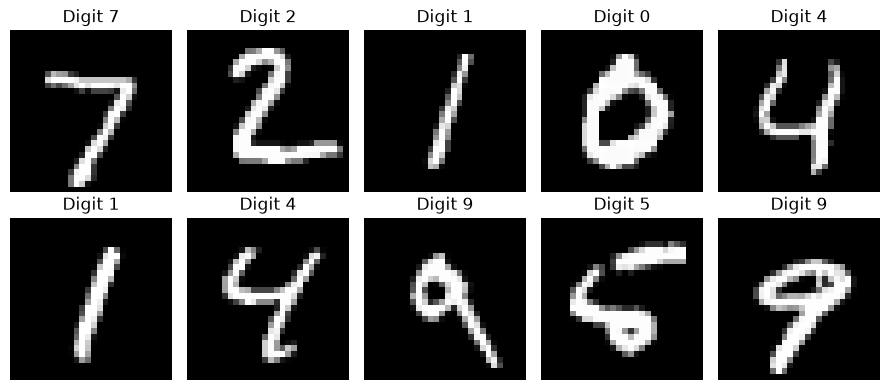

In [5]:
x_train, x_val, y_train, y_val = train_test_split(
    x_pool,
    y_pool,
    test_size=0.1,
    stratify=y_pool,
    random_state=SEED,
)
x_train = x_train.astype('float32')[..., None] / 255.0
x_val = x_val.astype('float32')[..., None] / 255.0
x_test = x_test.astype('float32')[..., None] / 255.0
print('Train:', x_train.shape, 'Validation:', x_val.shape, 'Test:', x_test.shape)
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i, ..., 0], cmap='gray')
    ax.set_title(f'Digit {y_test[i]}')
    ax.axis('off')
plt.tight_layout()
plt.show()


In [6]:
def build_ann():
    return keras.Sequential(
        [
            layers.Input((28, 28, 1)),
            layers.Flatten(),
            layers.Dense(256, activation='relu'),
            layers.Dropout(0.3),
            layers.Dense(128, activation='relu'),
            layers.Dropout(0.2),
            layers.Dense(10, activation='softmax'),
        ],
        name='ann',
    )


In [7]:
def build_basic_cnn():
    return keras.Sequential(
        [
            layers.Input((28, 28, 1)),
            layers.Conv2D(32, 3, activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Conv2D(64, 3, activation='relu', padding='same'),
            layers.MaxPooling2D(),
            layers.Flatten(),
            layers.Dense(128, activation='relu'),
            layers.Dropout(0.3),
            layers.Dense(10, activation='softmax'),
        ],
        name='basic_cnn',
    )


In [8]:
def build_lenet():
    return keras.Sequential(
        [
            layers.Input((28, 28, 1)),
            layers.Conv2D(6, 5, padding='same', activation='relu'),
            layers.AveragePooling2D(2),
            layers.Conv2D(16, 5, activation='relu'),
            layers.AveragePooling2D(2),
            layers.Conv2D(120, 5, activation='relu'),
            layers.Flatten(),
            layers.Dense(84, activation='relu'),
            layers.Dropout(0.25),
            layers.Dense(10, activation='softmax'),
        ],
        name='lenet5',
    )


In [9]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, metric in zip(axes, ('accuracy', 'loss')):
        if metric not in history.history:
            ax.axis('off')
            continue
        epochs = np.arange(1, len(history.history[metric]) + 1)
        ax.plot(epochs, history.history[metric], label='Train')
        ax.plot(epochs, history.history['val_' + metric], label='Validation')
        ax.set(title=f'{title}: {metric}', xlabel='Epoch', ylabel=metric.title())
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


Model: "ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
422/422 - 7s - 17ms/step - accuracy: 0.8876 - loss: 0.3748 - val_accuracy: 0.9542 - val_loss: 0.1592 - learning_rate: 0.0010
Epoch 2/50
422/422 - 4s - 10ms/step - accuracy: 0.9520 - loss: 0.1615 - val_accuracy: 0.9680 - val_loss: 0.1118 - learning_rate: 0.0010
Epoch 3/50
422/422 - 4s - 10ms/step - accuracy: 0.9634 - loss: 0.1222 - val_accuracy: 0.9702 - val_loss: 0.1012 - learning_rate: 0.0010
Epoch 4/50
422/422 - 4s - 9ms/step - accuracy: 0.9692 - loss: 0.0997 - val_accuracy: 0.9748 - val_loss: 0.0865 - learning_rate: 0.0010
Epoch 5/50
422/422 - 4s - 10ms/step - accuracy: 0.9741 - loss: 0.0829 - val_accuracy: 0.9760 - val_loss: 0.0889 - learning_rate: 0.0010
Epoch 6/50
422/422 - 4s - 9ms/step - accuracy: 0.9766 - loss: 0.0736 - val_accuracy: 0.9775 - val_loss: 0.0836 - learning_rate: 0.0010
Epoch 7/50
422/422 - 4s - 9ms/step - accuracy: 0.9795 - loss: 0.0644 - val_accuracy: 0.9783 - val_loss: 0.0795 - learning_rate: 0.0010
Epoch 8/50
422/422 - 4s - 9ms/step - accuracy: 0.98

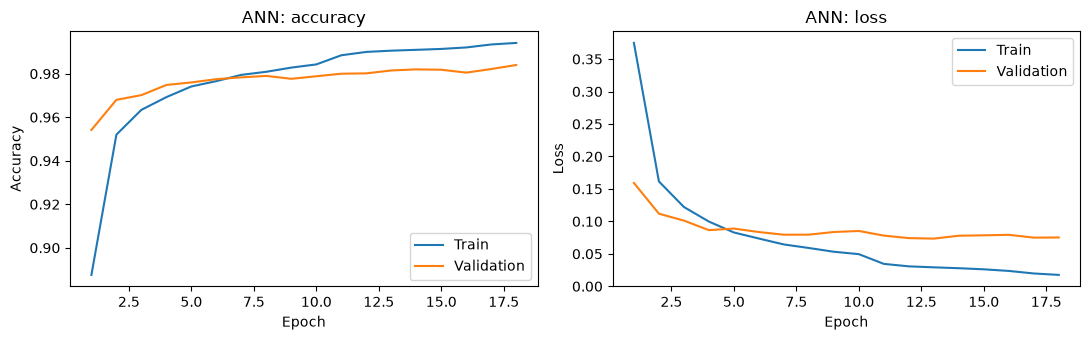

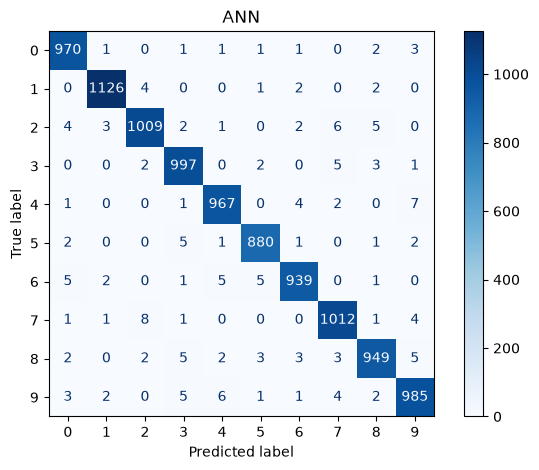

Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
422/422 - 28s - 67ms/step - accuracy: 0.9298 - loss: 0.2344 - val_accuracy: 0.9785 - val_loss: 0.0762 - learning_rate: 0.0010
Epoch 2/50
422/422 - 24s - 56ms/step - accuracy: 0.9785 - loss: 0.0713 - val_accuracy: 0.9860 - val_loss: 0.0531 - learning_rate: 0.0010
Epoch 3/50
422/422 - 24s - 57ms/step - accuracy: 0.9844 - loss: 0.0501 - val_accuracy: 0.9883 - val_loss: 0.0481 - learning_rate: 0.0010
Epoch 4/50
422/422 - 23s - 55ms/step - accuracy: 0.9877 - loss: 0.0395 - val_accuracy: 0.9888 - val_loss: 0.0438 - learning_rate: 0.0010
Epoch 5/50
422/422 - 23s - 53ms/step - accuracy: 0.9902 - loss: 0.0317 - val_accuracy: 0.9877 - val_loss: 0.0464 - learning_rate: 0.0010
Epoch 6/50
422/422 - 22s - 52ms/step - accuracy: 0.9911 - loss: 0.0280 - val_accuracy: 0.9898 - val_loss: 0.0379 - learning_rate: 0.0010
Epoch 7/50
422/422 - 22s - 53ms/step - accuracy: 0.9931 - loss: 0.0217 - val_accuracy: 0.9893 - val_loss: 0.0436 - learning_rate: 0.0010
Epoch 8/50
422/422 - 22s - 51ms/step - ac

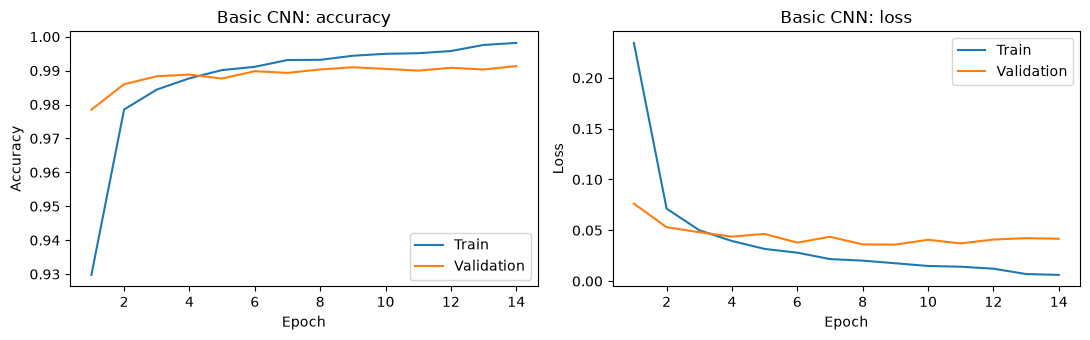

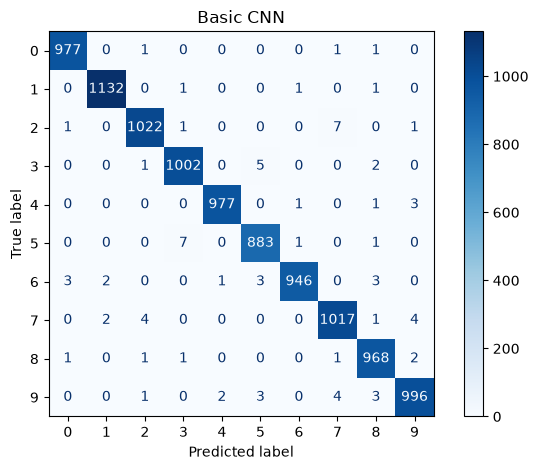

Model: "lenet5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 84)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
422/422 - 10s - 24ms/step - accuracy: 0.8693 - loss: 0.4318 - val_accuracy: 0.9630 - val_loss: 0.1301 - learning_rate: 0.0010
Epoch 2/50
422/422 - 8s - 18ms/step - accuracy: 0.9640 - loss: 0.1221 - val_accuracy: 0.9738 - val_loss: 0.0907 - learning_rate: 0.0010
Epoch 3/50
422/422 - 8s - 18ms/step - accuracy: 0.9731 - loss: 0.0895 - val_accuracy: 0.9798 - val_loss: 0.0714 - learning_rate: 0.0010
Epoch 4/50
422/422 - 9s - 21ms/step - accuracy: 0.9780 - loss: 0.0737 - val_accuracy: 0.9790 - val_loss: 0.0763 - learning_rate: 0.0010
Epoch 5/50
422/422 - 8s - 20ms/step - accuracy: 0.9818 - loss: 0.0602 - val_accuracy: 0.9820 - val_loss: 0.0650 - learning_rate: 0.0010
Epoch 6/50
422/422 - 8s - 19ms/step - accuracy: 0.9837 - loss: 0.0534 - val_accuracy: 0.9825 - val_loss: 0.0634 - learning_rate: 0.0010
Epoch 7/50
422/422 - 8s - 18ms/step - accuracy: 0.9861 - loss: 0.0464 - val_accuracy: 0.9852 - val_loss: 0.0544 - learning_rate: 0.0010
Epoch 8/50
422/422 - 8s - 18ms/step - accuracy:

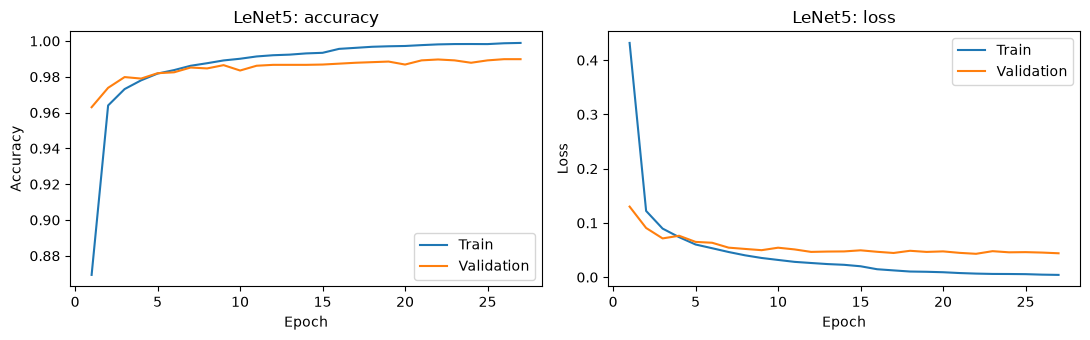

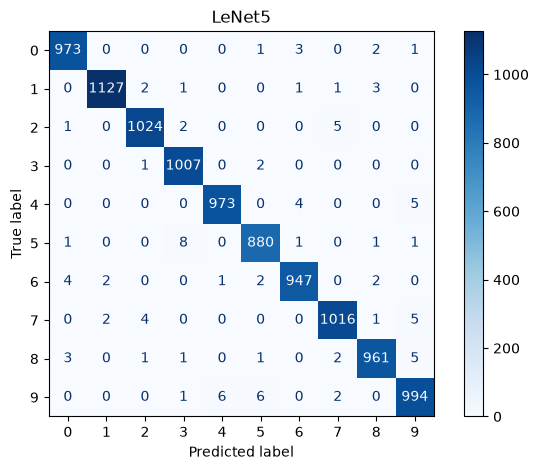

In [10]:
models = {}
histories = {}
rows = []
for name, builder in {
    'ANN': build_ann,
    'Basic CNN': build_basic_cnn,
    'LeNet5': build_lenet,
}.items():
    keras.utils.set_random_seed(SEED)
    model = builder()
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    model.summary()
    history = model.fit(
        x_train,
        y_train,
        validation_data=(x_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=2,
        callbacks=[
            early_stopping(),
            keras.callbacks.ReduceLROnPlateau(patience=3, factor=0.5, min_lr=1e-06),
        ],
    )
    loss, _ = model.evaluate(x_test, y_test, verbose=0)
    predictions = model.predict(x_test, verbose=0).argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_test,
        predictions,
        average='macro',
        zero_division=0,
    )
    rows.append(
        {
            'Model': name,
            'Loss': loss,
            'Accuracy': accuracy_score(y_test, predictions),
            'Precision': precision,
            'Recall': recall,
            'F1': f1,
        },
    )
    print(classification_report(y_test, predictions, digits=4, zero_division=0))
    plot_history(history, name)
    ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap='Blues')
    plt.title(name)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / f'{model.name}_confusion.png', dpi=150)
    plt.show()
    model.save(OUTPUT_DIR / f'{model.name}.keras')
    pd.DataFrame(history.history).to_csv(
        OUTPUT_DIR / f'{model.name}_history.csv',
        index=False,
    )
    models[name], histories[name] = (model, history)


In [11]:
comparison = pd.DataFrame(rows).set_index('Model')
comparison.to_csv(OUTPUT_DIR / 'comparison.csv')
display(comparison.round(4))


,Loss,Accuracy,Precision,Recall,F1
Model,,,,,
ANN,0.0595,0.9834,0.9833,0.9833,0.9833
Basic CNN,0.0248,0.9920,0.9919,0.9919,0.9919
LeNet5,0.0382,0.9902,0.9901,0.9901,0.9901


In [12]:
IMAGE_PATH = None
MODEL_NAME = 'Basic CNN'


In [13]:
def predict_digit(path, model):
    with Image.open(path) as image:
        image = ImageOps.grayscale(image)
        image = image.resize((28, 28), Image.Resampling.LANCZOS)
        pixels = np.asarray(image, dtype='float32')
    border = np.concatenate([pixels[0], pixels[-1], pixels[:, 0], pixels[:, -1]])
    if border.mean() > 127:
        pixels = 255.0 - pixels
    pixels /= 255.0
    probabilities = model.predict(pixels[None, ..., None], verbose=0)[0]
    digit = int(probabilities.argmax())
    plt.imshow(pixels, cmap='gray')
    plt.title(f'Prediction: {digit} ({probabilities[digit]:.1%})')
    plt.axis('off')
    plt.show()
    return (digit, probabilities)


In [14]:
if IMAGE_PATH is not None:
    predict_digit(IMAGE_PATH, models[MODEL_NAME])
